# Reading Zarr arrays and CT volumes
Open a published Zarr group, select a stored pyramid level, read slices and several
blocks, reuse a bounded chunk cache, and reopen cached data offline. These reader
operations also accept a local path or an S3 URL. No PyTorch is needed.


In [1]:
from pathlib import Path
import os

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
options = dict(cache_dir=CACHE, threads=1,
               memory_cache=MemoryCache(64 << 20))
catalog = load(METADATA) if METADATA else load()


## 1. Discover a volume, then open its Zarr group
Discovery identifies the URL; the general reader can also open a caller-provided
`/path/to/volume.zarr`, `https://...` or `s3://...` location. Opening a group reads
metadata. Selecting level 2 uses a stored array and does not resize a level-0 crop.


In [2]:
from vc_reader.reader import ZarrGroup, ZarrReader
volume = catalog.samples['PHercParis4'].volumes['20260411134726']
location = volume.source.storage.location
print('Volume:', volume.id)
print('Location:', location)
with ZarrGroup.open(location, **options) as group:
    print('Stored levels:', group.levels)
    array = group.level(2)
    print('ZYX shape:', array.shape, 'chunks:', array.chunks, 'dtype:', array.dtype)
    array_location = array.location  # direct array URL, for ZarrReader.open below


Volume: 20260411134726
Location: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/volumes/20260411134726-2.400um-0.2m-78keV-masked.zarr/


Stored levels: ('0', '1', '2', '3', '4', '5')


ZYX shape: (18946, 8174, 8174) chunks: (128, 128, 128) dtype: uint8


## 2. Read an axial slice with indexing
Array indexing follows the stored axes (ZYX for this CT). An integer Z index
returns a 2D YX slice.


Axial slice: (256, 256)


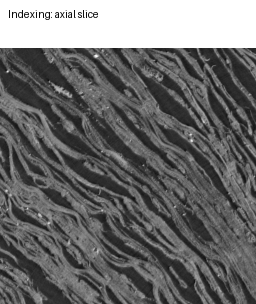

In [3]:
with ZarrReader.open(array_location, **options) as reader:
    axial = reader[9064, 3600:3856, 3600:3856]
print('Axial slice:', axial.shape)
display(panel([('Indexing: axial slice', axial)], vmin=0, vmax=255))


## 3. Read a 3D block with slicing
Use NumPy-style `reader[z_start:z_stop, y_start:y_stop, x_start:x_stop]` indexing.
Three slices preserve all three axes. Read a 128³ block and display its central
Z (YX), Y (ZX), and X (ZY) slices.


3D block: (128, 128, 128)


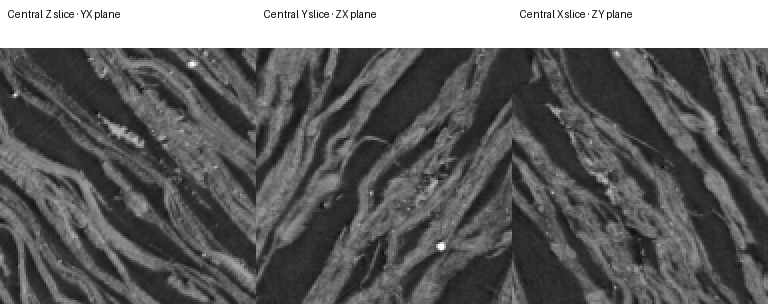

In [4]:
with ZarrReader.open(array_location, **options) as reader:
    block = reader[9000:9128, 3600:3728, 3600:3728]
print('3D block:', block.shape)
z, y, x = (length // 2 for length in block.shape)
display(panel([('Central Z slice · YX plane', block[z, :, :]),
               ('Central Y slice · ZX plane', block[:, y, :]),
               ('Central X slice · ZY plane', block[:, :, x])], vmin=0, vmax=255))


## 4. Batch multiple overlapping blocks
Use `np.s_` to store slice selections, then pass them to `read_many`.
Overlapping chunks are read once for the batch. The bounded cache also shares
chunks across calls; output memory is separate from that cache.


Batch blocks: [(128, 128, 128), (128, 128, 128)]
Cache/I/O counters: {'memory_hits': 8, 'pending_hits': 0, 'pending_writes': 0, 'disk_hits': 0, 'remote_fetches': 0, 'remote_missing': 0, 'remote_bytes': 0, 'write_errors': 0, 'last_write_error': ''}


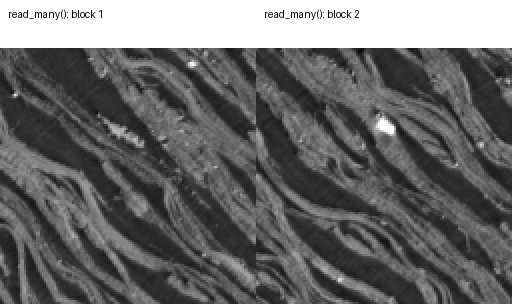

In [5]:
crops = [np.s_[9000:9128, 3600:3728, 3600:3728],
         np.s_[9032:9160, 3632:3760, 3632:3760]]
with ZarrReader.open(array_location, **options) as reader:
    patches = reader.read_many(crops)
    stats = reader.stats()
print('Batch blocks:', [patch.shape for patch in patches])
print('Cache/I/O counters:', stats)
display(panel([(f'read_many(): block {i + 1}', patch[patch.shape[0] // 2])
               for i, patch in enumerate(patches)], vmin=0, vmax=255))


## 5. Read directly into float32 output
Pass a slice selection and `dtype=np.float32` to `read` to convert directly into
the output allocation. Stored intensity values are preserved; this crop matches
the first batched block.


Output dtype: float32


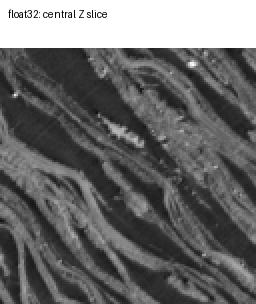

In [6]:
with ZarrReader.open(array_location, **options) as reader:
    float_patch = reader.read(crops[0], dtype=np.float32)
np.testing.assert_array_equal(float_patch, patches[0])
print('Output dtype:', float_patch.dtype)
display(panel([('float32: central Z slice', float_patch[float_patch.shape[0] // 2])],
              vmin=0, vmax=255))


## 6. Reuse a destination buffer
Pass the same slice selection with `out=buffer` to fill an existing allocation
directly. Its contents are replaced on the next write. Keep a copy here for the
offline check.


Returned array shares the destination buffer: True


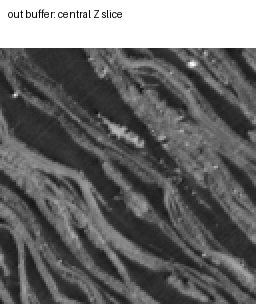

In [7]:
buffer = np.empty((128, 128, 128), dtype=np.float32)
with ZarrReader.open(array_location, **options) as reader:
    returned = reader.read(crops[0], out=buffer, dtype=np.float32)
assert np.shares_memory(returned, buffer)
expected = buffer.copy()
print('Returned array shares the destination buffer:', np.shares_memory(returned, buffer))
display(panel([('out buffer: central Z slice', buffer[buffer.shape[0] // 2])],
              vmin=0, vmax=255))


## 7. Reopen cached data offline
Offline opening requires cached headers **and** the chunks requested; it does
not download them. The preceding reads have populated the cache for this crop.


Offline crop equals online/cached crop; shared cache bytes: 27262976


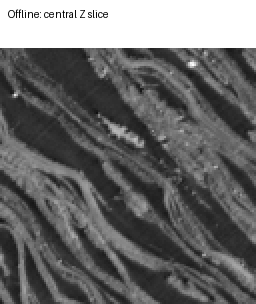

In [8]:
with ZarrReader.open(array_location, **{**options, 'offline': True}) as reader:
    cached = reader[9000:9128, 3600:3728, 3600:3728]
np.testing.assert_array_equal(cached, expected)
print('Offline crop equals online/cached crop; shared cache bytes:', options['memory_cache'].nbytes)
display(panel([('Offline: central Z slice', cached[cached.shape[0] // 2])],
              vmin=0, vmax=255))


## 8. Read through a discovered volume
Use the browsing view for catalog ownership and stored-level selection, or
`ZarrGroup`/`ZarrReader` for general arrays. Both paths use the same storage
reader. Context managers close reader resources after each example.


Catalog and direct Zarr reads agree.


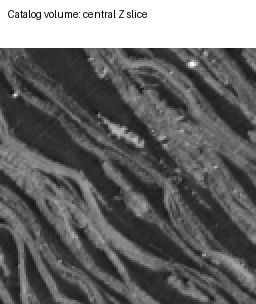

In [9]:
with volume.open(level=2, **options) as reader:
    discovered = reader[9000:9128, 3600:3728, 3600:3728]
np.testing.assert_array_equal(discovered, patches[0])
print('Catalog and direct Zarr reads agree.')
display(panel([('Catalog volume: central Z slice', discovered[discovered.shape[0] // 2])],
              vmin=0, vmax=255))
